# 01 · Exploratory analysis of the Amazon Last Mile data

What does a real last-mile day look like, and which properties must our generator and models
respect? Data: training split processed by `nr-etl` (see `docs/decisions.md`).

In [1]:
import os
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir("..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from neural_routing.data.amazon import AmazonDataset, haversine_km

sns.set_theme(style="whitegrid", context="notebook")
FIG = Path("docs/figures")
FIG.mkdir(parents=True, exist_ok=True)
ds = AmazonDataset("training")
routes, stops = ds.routes, ds.stops
packages = pd.read_parquet("data/processed/training/packages.parquet")
print(
    f"{len(routes):,} routes · {len(stops):,} stops · {len(packages):,} packages · "
    f"{routes.station_code.nunique()} stations · {routes.date.nunique()} days"
)

6,112 routes · 904,527 stops · 1,457,175 packages · 17 stations · 39 days


## 1. Scale: routes, stops and stations

count    6112.0
mean      147.0
std        31.0
min        32.0
25%       128.0
50%       150.0
75%       169.0
max       237.0
Name: n_nodes, dtype: float64

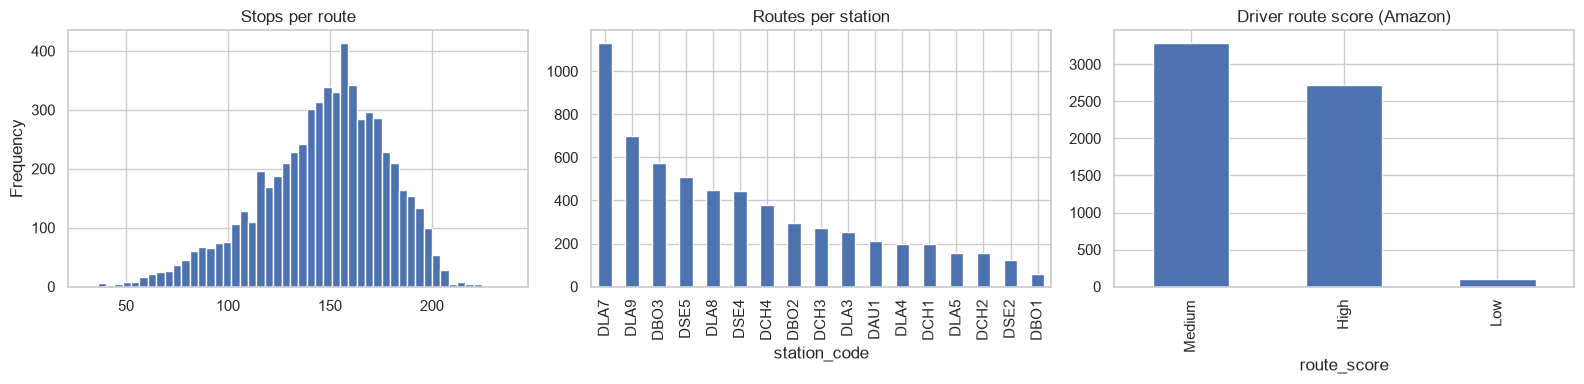

In [2]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
(routes.n_nodes - 1).plot.hist(bins=50, ax=ax[0], title="Stops per route")
routes.station_code.value_counts().plot.bar(ax=ax[1], title="Routes per station")
routes.route_score.value_counts().plot.bar(ax=ax[2], title="Driver route score (Amazon)")
plt.tight_layout()
plt.savefig(FIG / "eda_scale.png", dpi=120)
(routes.n_nodes - 1).describe().round(1)

In [3]:
days = ds.station_days()
print("Routes per station-day:")
print(days.num_routes.describe().round(1))
print("\nStops per station-day:")
print(days.num_stops.describe().round(0))

Routes per station-day:
count    521.0
mean      11.7
std        9.8
min        1.0
25%        5.0
50%       10.0
75%       15.0
max       56.0
Name: num_routes, dtype: float64

Stops per station-day:
count     521.0
mean     1736.0
std      1515.0
min        59.0
25%       641.0
50%      1398.0
75%      2253.0
max      8685.0
Name: num_stops, dtype: float64


**Takeaway.** A route has ~150 stops (far above the 20–100 nodes used in most neural routing
papers), and a whole station-day can exceed a thousand stops. Size generalisation is the main
modelling risk, so the curriculum must reach 100–200 nodes.

## 2. Geography of one station-day

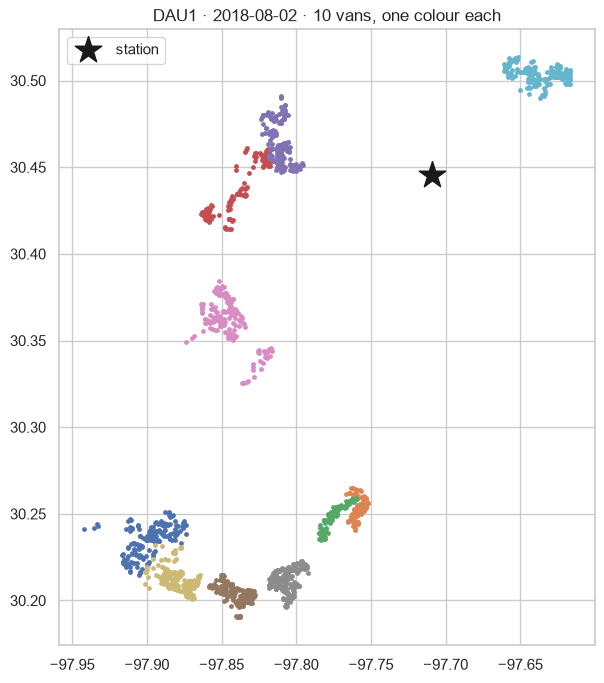

In [4]:
station, date = days.sort_values("num_routes").iloc[len(days) // 2][["station_code", "date"]]
day = routes[(routes.station_code == station) & (routes.date == date)].index
s = stops[stops.route_id.isin(day)]
fig, ax = plt.subplots(figsize=(8, 8))
for _rid, g in s[s.type == "Dropoff"].groupby("route_id"):
    ax.scatter(g.lng, g.lat, s=6)
st = s[s.type == "Station"].iloc[0]
ax.scatter(st.lng, st.lat, marker="*", s=400, c="k", label="station")
ax.set_title(f"{station} · {date} · {len(day)} vans, one colour each")
ax.legend()
ax.set_aspect(1 / np.cos(np.radians(st.lat)))
plt.savefig(FIG / "eda_station_day.png", dpi=120)

Each van serves a compact cluster far from the station: a long *stem* trip, then dense local
delivery. That structure (clusters + remote depot) is what the synthetic generator must
reproduce; uniform random points do not look like this.

## 3. Demand and capacity

median utilisation 74% · routes over capacity 0.2%


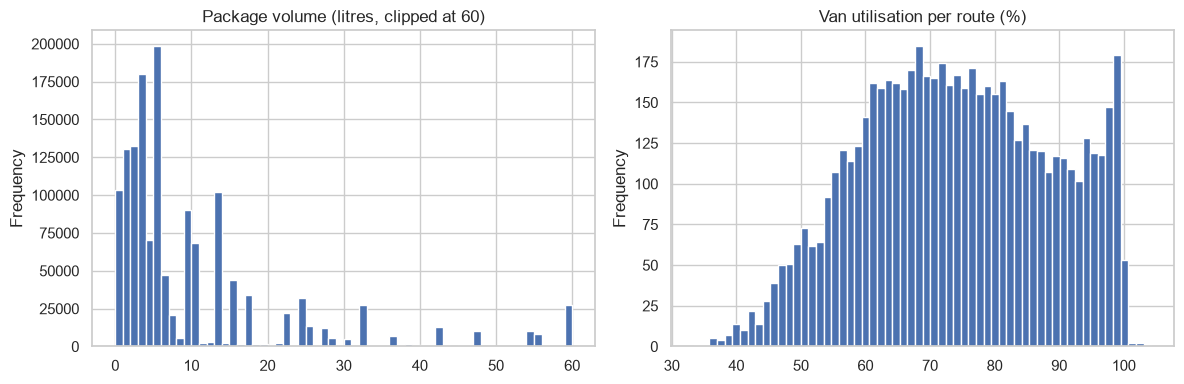

In [5]:
per_route = stops.groupby("route_id").volume_cm3.sum()
util = (per_route / routes.capacity_cm3).dropna()
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
(packages.volume_cm3 / 1000).clip(upper=60).plot.hist(
    bins=60, ax=ax[0], title="Package volume (litres, clipped at 60)"
)
(100 * util).clip(upper=150).plot.hist(bins=60, ax=ax[1], title="Van utilisation per route (%)")
plt.tight_layout()
plt.savefig(FIG / "eda_capacity.png", dpi=120)
print(
    f"median utilisation {100 * util.median():.0f}% · routes over capacity {100 * (util > 1).mean():.1f}%"
)

Vans leave about three-quarters full (median 74%) and almost never above nominal volume, so in the single-van view capacity rarely binds, while in the pooled station-day view it decides how many vans are needed.

## 4. Time windows

packages with a window: 7.8% · stops with a window: 6.6%


count    113993.00
mean          9.00
std           4.59
min           3.50
25%           7.00
50%           8.00
75%           8.50
max          23.98
dtype: float64

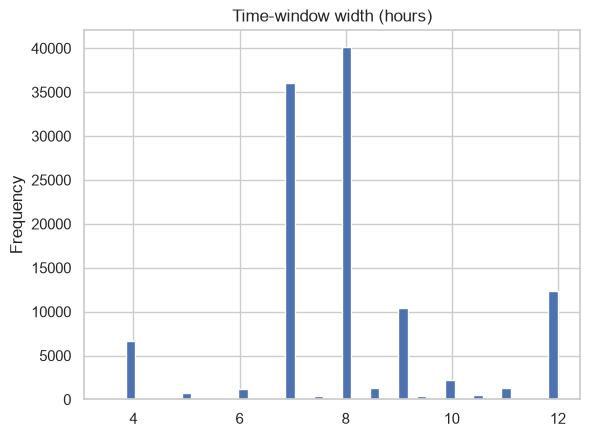

In [6]:
has_tw = packages.tw_end_s.notna()
width_h = (packages.tw_end_s - packages.tw_start_s)[has_tw] / 3600
stop_tw = stops[stops.type == "Dropoff"].tw_end_s.notna()
print(
    f"packages with a window: {100 * has_tw.mean():.1f}% · stops with a window: {100 * stop_tw.mean():.1f}%"
)
ax = width_h.clip(upper=12).plot.hist(bins=48, title="Time-window width (hours)")
plt.savefig(FIG / "eda_time_windows.png", dpi=120)
width_h.describe().round(2)

## 5. Real travel time vs straight-line distance

median relative asymmetry |t_ij - t_ji| / mean: 6.1%


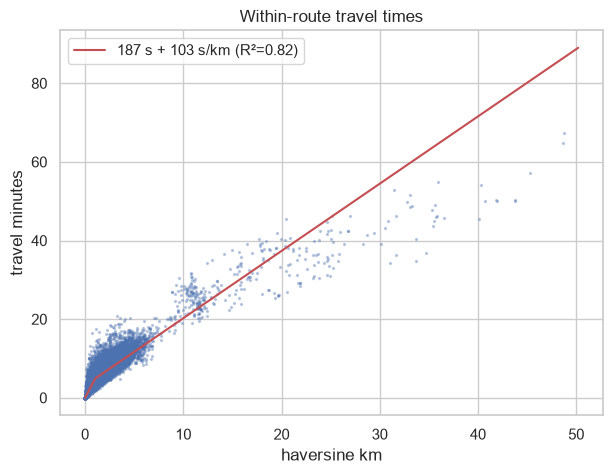

In [7]:
model = ds.fit_travel_model(num_routes=300)
rng = np.random.default_rng(0)
km, sec = [], []
for rid in rng.choice(routes.index, 100, replace=False):
    g = stops[stops.route_id == rid].sort_values("node")
    xy = g[["lat", "lng"]].to_numpy()
    km.append(haversine_km(xy, xy).ravel())
    sec.append(ds.durations(rid).ravel())
km, sec = np.concatenate(km), np.concatenate(sec)
pred = model.predict(km)
r2 = 1 - ((sec - pred) ** 2).sum() / ((sec - sec.mean()) ** 2).sum()
idx = rng.choice(len(km), 20000, replace=False)
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(km[idx], sec[idx] / 60, s=2, alpha=0.3)
x = np.linspace(0, km.max(), 50)
ax.plot(
    x,
    model.predict(x) / 60,
    "r",
    label=f"{model.intercept:.0f} s + {model.slope:.0f} s/km (R²={r2:.2f})",
)
ax.set(xlabel="haversine km", ylabel="travel minutes", title="Within-route travel times")
ax.legend()
plt.savefig(FIG / "eda_travel_model.png", dpi=120)
asym = []
for rid in routes.index[:200]:
    D = ds.durations(rid)
    m = D + D.T > 0
    asym.append(np.median(np.abs(D - D.T)[m] / ((D + D.T)[m] / 2)))
print(f"median relative asymmetry |t_ij - t_ji| / mean: {100 * np.median(asym):.1f}%")

A straight-line model explains most of the variance, which is what lets us pool routes
(ADR-005), but the matrices are asymmetric, so a model that only sees coordinates leaves value
on the table. This motivates the matrix-aware encoder planned for phase 4.

## 6. How do drivers actually drive?

In [8]:
def zone_stats(rid):
    g = stops[(stops.route_id == rid) & (stops.actual_order > 0)].sort_values("actual_order")
    z = g.zone_id.fillna("?").to_numpy()
    return len(set(z)), int((z[1:] != z[:-1]).sum())


zs = pd.DataFrame([zone_stats(r) for r in routes.index[:1000]], columns=["zones", "switches"])
zs["excess_switches"] = zs.switches - (zs.zones - 1)
print(zs.describe().round(2))
print(
    f"routes where the driver never re-enters a zone: {100 * (zs.excess_switches == 0).mean():.0f}%"
)

         zones  switches  excess_switches
count  1000.00   1000.00          1000.00
mean     20.61     21.76             2.15
std       5.40      6.76             3.69
min       4.00      3.00             0.00
25%      17.00     18.00             0.00
50%      21.00     21.00             1.00
75%      24.00     25.00             3.00
max      44.00     60.00            45.00
routes where the driver never re-enters a zone: 42%


Drivers mostly finish one delivery zone before moving to the next. That is a strong human
prior: an optimiser minimising travel time alone may zig-zag between zones. The benchmark therefore
reports both travel time *and* closeness to the driver; a zone-aware objective is a later extension.